# 🏈 NFL Play by Play 2009–2017 (v4) — do CSV bruto ao Parquet confiável

**Autor:** Rafael &nbsp;·&nbsp; **Dataset:** *NFL Play by Play 2009-2017 (v4)* (Kaggle) &nbsp;·&nbsp; **Ferramentas:** Python, pandas, PyArrow

> **Resumo.** Neste notebook preparo o conjunto de dados de jogadas da NFL para ficar **consistente, confiável e otimizado para armazenamento**. Cada decisão (tipo de dado, tratamento de ausentes, limpeza) é **justificada em Markdown** e **comprovada por um teste no código**. No final comparo o tamanho do CSV original com o Parquet e valido que nada foi perdido ao gravar e reler o arquivo.

### Sumário
1. [Preparação e carregamento](#1)
2. [Diagnóstico dos dados](#2)
3. [Tipificação](#3)
4. [Tratamento de valores ausentes](#4)
5. [Limpeza dos dados](#5)
6. [Otimização de memória](#6)
7. [Armazenamento em Parquet](#7)
8. [Validação após o armazenamento](#8)
9. [Análise final](#9)

### Princípios que guiam todas as decisões
* **Nunca alterar o arquivo original**: trabalho sempre numa cópia (`df`), mantendo o `bruto` para comparar.
* **Significado antes de tipo**: o tipo de cada coluna é escolhido pelo que ela *representa*, não pelo que o pandas inferiu.
* **Ausência nem sempre é problema**: numa base de jogadas, muito `NaN` apenas significa *"isso não se aplica a essa jogada"*.
* **Toda mudança é medida**: registro quantos valores foram alterados em cada passo (tabela `log`) e confirmo que os valores válidos foram preservados.
* **Nada de imputação sem justificativa semântica**: inventar dados piora a confiabilidade.

In [8]:
pip install numpy pandas pyarrow matplotlib

<a id="1"></a>
## 1. Preparação e carregamento

**Objetivo:** carregar o CSV original sem modificá-lo e registrar a "linha de base" (linhas, colunas, memória, tamanho em disco) contra a qual todas as melhorias serão medidas.

**Cuidados:**
* `low_memory=False` faz o pandas ler o arquivo inteiro antes de inferir tipos, evitando o aviso de *tipos mistos* (que aparece nesse dataset em colunas como `DefTwoPoint` e `BlockingPlayer`).
* O caminho é procurado automaticamente (Colab, Kaggle ou pasta local).

In [9]:
# Bibliotecas e configurações de exibição
import glob, time, warnings, re
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 120)
pd.set_option("display.max_rows", 150)
pd.set_option("display.float_format", "{:,.3f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

MB = 1024 ** 2  # 1 MiB em bytes (mesma unidade usada em aula)

def md(texto):
    """Mostra um texto em Markdown como saída da célula (usado nos resumos automáticos)."""
    display(Markdown(texto))

# Registro de TODAS as transformações feitas nos dados (alimenta a análise final)
log = []
def registrar(etapa, coluna, quantidade, detalhe=""):
    log.append({"etapa": etapa, "coluna": coluna, "quantidade": int(quantidade), "detalhe": detalhe})

print("pandas", pd.__version__, "| pyarrow", pa.__version__)

pandas 2.2.3 | pyarrow 23.0.1


In [10]:
# Localiza o CSV original (Colab, Kaggle ou pasta local)
def localizar_csv():
    preferido = Path("/content/NFL Play by Play 2009-2017 (v4).csv")
    if preferido.exists():
        return preferido
    for padrao in ["/kaggle/input/**/*.csv", "/content/**/*Play*by*Play*.csv", "./**/*Play*by*Play*.csv"]:
        achados = sorted(glob.glob(padrao, recursive=True))
        if achados:
            return Path(achados[0])
    raise FileNotFoundError("CSV da NFL não encontrado. Ajuste o caminho em `arquivo_csv`.")

arquivo_csv = localizar_csv()

# Pasta de saída (Kaggle só permite gravar em /kaggle/working)
if Path("/kaggle/working").exists():   OUT_DIR = Path("/kaggle/working")
elif Path("/content").exists():        OUT_DIR = Path("/content")
else:                                  OUT_DIR = Path(".")

# Leitura do CSV bruto: este DataFrame NÃO será alterado (é a referência)
bruto = pd.read_csv(arquivo_csv, low_memory=False)

# Linha de base para as comparações finais
base = {
    "csv_bytes": arquivo_csv.stat().st_size,
    "linhas": bruto.shape[0],
    "colunas": bruto.shape[1],
    "memoria_bytes": int(bruto.memory_usage(deep=True).sum()),
    "ausentes": int(bruto.isna().sum().sum()),
}
md(f"""
**Arquivo:** `{arquivo_csv.name}` &nbsp;|&nbsp; **Tamanho em disco:** {base['csv_bytes']/MB:,.2f} MiB
**Dimensões:** {base['linhas']:,} linhas × {base['colunas']} colunas &nbsp;|&nbsp; **Memória no pandas:** {base['memoria_bytes']/MB:,.1f} MiB
**Pasta de saída:** `{OUT_DIR}`
""")


**Arquivo:** `NFL Play by Play 2009-2017 (v4).csv` &nbsp;|&nbsp; **Tamanho em disco:** 34.00 MiB  
**Dimensões:** 51,429 linhas × 102 colunas &nbsp;|&nbsp; **Memória no pandas:** 102.9 MiB  
**Pasta de saída:** `/content`


<a id="2"></a>
## 2. Diagnóstico dos dados

**Objetivo:** entender o que cada linha representa e mapear estrutura, tipos, ausências e possíveis inconsistências **antes de mexer em qualquer coisa**.

**Unidade de observação:** cada linha é **uma jogada (play)** de uma partida da NFL. Por isso `GameID` e `Drive` se repetem muitas vezes — isso é natural e **não é duplicidade**.

In [11]:
# 2.1 Visão geral: amostra e distribuição dos tipos atuais
display(bruto.head())
tipos_atuais = bruto.dtypes.astype(str).value_counts().rename("colunas").to_frame()
display(tipos_atuais)

,Date,GameID,Drive,qtr,down,time,TimeUnder,TimeSecs,PlayTimeDiff,SideofField,yrdln,yrdline100,ydstogo,ydsnet,GoalToGo,FirstDown,posteam,DefensiveTeam,desc,PlayAttempted,Yards.Gained,sp,Touchdown,ExPointResult,TwoPointConv,DefTwoPoint,Safety,Onsidekick,PuntResult,PlayType,Passer,Passer_ID,PassAttempt,PassOutcome,PassLength,AirYards,YardsAfterCatch,QBHit,PassLocation,InterceptionThrown,Interceptor,Rusher,Rusher_ID,RushAttempt,RunLocation,RunGap,Receiver,Receiver_ID,Reception,ReturnResult,Returner,BlockingPlayer,Tackler1,Tackler2,FieldGoalResult,FieldGoalDistance,Fumble,RecFumbTeam,RecFumbPlayer,Sack,Challenge.Replay,ChalReplayResult,Accepted.Penalty,PenalizedTeam,PenaltyType,PenalizedPlayer,Penalty.Yards,PosTeamScore,DefTeamScore,ScoreDiff,AbsScoreDiff,HomeTeam,AwayTeam,Timeout_Indicator,Timeout_Team,posteam_timeouts_pre,HomeTimeouts_Remaining_Pre,AwayTimeouts_Remaining_Pre,HomeTimeouts_Remaining_Post,AwayTimeouts_Remaining_Post,No_Score_Prob,Opp_Field_Goal_Prob,Opp_Safety_Prob,Opp_Touchdown_Prob,Field_Goal_Prob,Safety_Prob,Touchdown_Prob,ExPoint_Prob,TwoPoint_Prob,ExpPts,EPA,airEPA,yacEPA,Home_WP_pre,Away_WP_pre,Home_WP_post,Away_WP_post,Win_Prob,WPA,airWPA,yacWPA,Season
0,2009-09-10,2009091000,1,1,NaN,15:00,15,"3,600.000",0.000,TEN,30.000,30.000,0,0,0.000,NaN,PIT,TEN,R.Bironas kicks 67 yards from TEN 30 to PIT 3....,1.000,39.000,0.000,0.000,NaN,NaN,NaN,0.000,0.000,NaN,Kickoff,NaN,NaN,0.000,NaN,NaN,0.000,0.000,0.000,NaN,0.000,NaN,NaN,NaN,0.000,NaN,NaN,NaN,NaN,0.000,NaN,S.Logan,NaN,M.Griffin,NaN,NaN,NaN,0.000,NaN,NaN,0.000,0.000,NaN,0.000,NaN,NaN,NaN,0.000,0.000,0.000,0.000,0.000,PIT,TEN,0.000,NaN,3.000,3.000,3.000,3.000,3.000,0.002,0.180,0.007,0.281,0.214,0.004,0.314,0.000,0.000,0.324,2.014,NaN,NaN,0.486,0.514,0.546,0.454,0.486,0.061,NaN,NaN,"2,009.000"
1,2009-09-10,2009091000,1,1,1.000,14:53,15,"3,593.000",7.000,PIT,42.000,58.000,10,5,0.000,0.000,PIT,TEN,(14:53) B.Roethlisberger pass short left to H....,1.000,5.000,0.000,0.000,NaN,NaN,NaN,0.000,0.000,NaN,Pass,B.Roethlisberger,00-0022924,1.000,Complete,Short,-3.000,8.000,0.000,left,0.000,NaN,NaN,NaN,0.000,NaN,NaN,H.Ward,00-0017162,1.000,NaN,NaN,NaN,C.Hope,NaN,NaN,NaN,0.000,NaN,NaN,0.000,0.000,NaN,0.000,NaN,NaN,NaN,0.000,0.000,0.000,0.000,0.000,PIT,TEN,0.000,NaN,3.000,3.000,3.000,3.000,3.000,0.001,0.109,0.001,0.169,0.294,0.004,0.423,0.000,0.000,2.338,0.078,-1.068,1.146,0.546,0.454,0.551,0.449,0.546,0.005,-0.032,0.037,"2,009.000"
2,2009-09-10,2009091000,1,1,2.000,14:16,15,"3,556.000",37.000,PIT,47.000,53.000,5,2,0.000,0.000,PIT,TEN,(14:16) W.Parker right end to PIT 44 for -3 ya...,1.000,-3.000,0.000,0.000,NaN,NaN,NaN,0.000,0.000,NaN,Run,NaN,NaN,0.000,NaN,NaN,0.000,0.000,0.000,NaN,0.000,NaN,W.Parker,00-0022250,1.000,right,end,NaN,NaN,0.000,NaN,NaN,NaN,S.Tulloch,NaN,NaN,NaN,0.000,NaN,NaN,0.000,0.000,NaN,0.000,NaN,NaN,NaN,0.000,0.000,0.000,0.000,0.000,PIT,TEN,0.000,NaN,3.000,3.000,3.000,3.000,3.000,0.001,0.105,0.001,0.163,0.305,0.004,0.421,0.000,0.000,2.416,-1.403,NaN,NaN,0.551,0.449,0.511,0.489,0.551,-0.040,NaN,NaN,"2,009.000"
3,2009-09-10,2009091000,1,1,3.000,13:35,14,"3,515.000",41.000,PIT,44.000,56.000,8,2,0.000,0.000,PIT,TEN,(13:35) (Shotgun) B.Roethlisberger pass incomp...,1.000,0.000,0.000,0.000,NaN,NaN,NaN,0.000,0.000,NaN,Pass,B.Roethlisberger,00-0022924,1.000,Incomplete Pass,Deep,34.000,0.000,0.000,right,0.000,NaN,NaN,NaN,0.000,NaN,NaN,M.Wallace,00-0026901,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000,NaN,NaN,0.000,0.000,NaN,0.000,NaN,NaN,NaN,0.000,0.000,0.000,0.000,0.000,PIT,TEN,0.000,NaN,3.000,3.000,3.000,3.000,3.000,0.001,0.149,0.002,0.235,0.289,0.005,0.319,0.000,0.000,1.013,-1.713,3.319,-5.031,0.511,0.489,0.461,0.539,0.511,-0.050,0.107,-0.156,"2,009.000"
4,2009-09-10,2009091000,1,1,4.000,13:27,14,"3,507.000",8.000,PIT,44.000,56.000,8,2,0.000,1.000,PIT,TEN,(13:27) (Punt formation) D.Sepulveda punts 54 ...,1.000,0.000,0.000,0.000,NaN,NaN,NaN,0.000,0.000,Clean,Punt,NaN,NaN,0.000,NaN,NaN,0.000,0.000,0.000,NaN,0.000,NaN,NaN,NaN,0.000,NaN,NaN,NaN,NaN,0.000,NaN,NaN,NaN,NaN,NaN,NaN,N

,colunas
float64,59
object,37
int64,6


,dtype,n_unicos,ausentes,pct_ausentes,mem_MiB
desc,object,48442,0,0.000,6.470
Date,object,48,0,0.000,2.894
time,object,901,34,0.066,2.648
PlayType,object,15,1,0.002,2.636
AwayTeam,object,32,1,0.002,2.540
HomeTeam,object,32,1,0.002,2.539
SideofField,object,34,71,0.138,2.539
DefensiveTeam,object,32,3380,6.572,2.476
posteam,object,32,3380,6.572,2.476
Tackler1,object,1415,19961,38.813,2.331


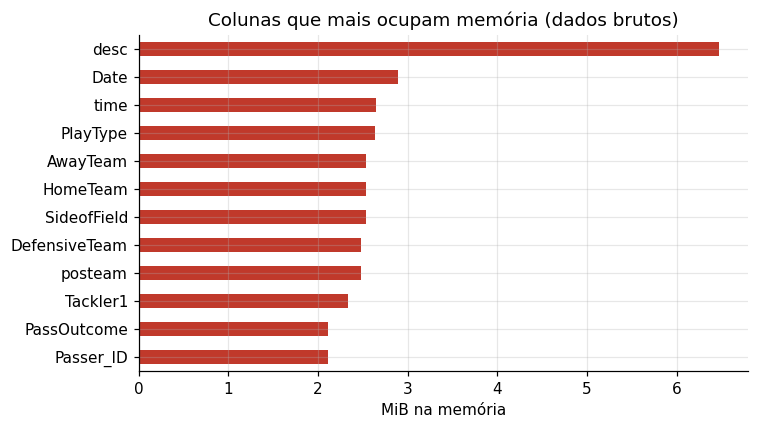

In [12]:
# 2.2 Perfil de cada coluna: tipo, cardinalidade, ausentes e peso na memória
perfil = pd.DataFrame({
    "dtype": bruto.dtypes.astype(str),
    "n_unicos": bruto.nunique(dropna=True),
    "ausentes": bruto.isna().sum(),
    "pct_ausentes": bruto.isna().mean() * 100,
    "mem_MiB": bruto.memory_usage(deep=True, index=False) / MB,
})
display(perfil.sort_values("mem_MiB", ascending=False).head(15))

# Gráfico: quais colunas mais pesam na memória
top = perfil.sort_values("mem_MiB").tail(12)
ax = top["mem_MiB"].plot.barh(figsize=(7, 4), color="#c0392b")
ax.set_xlabel("MiB na memória"); ax.set_title("Colunas que mais ocupam memória (dados brutos)")
plt.tight_layout(); plt.show()

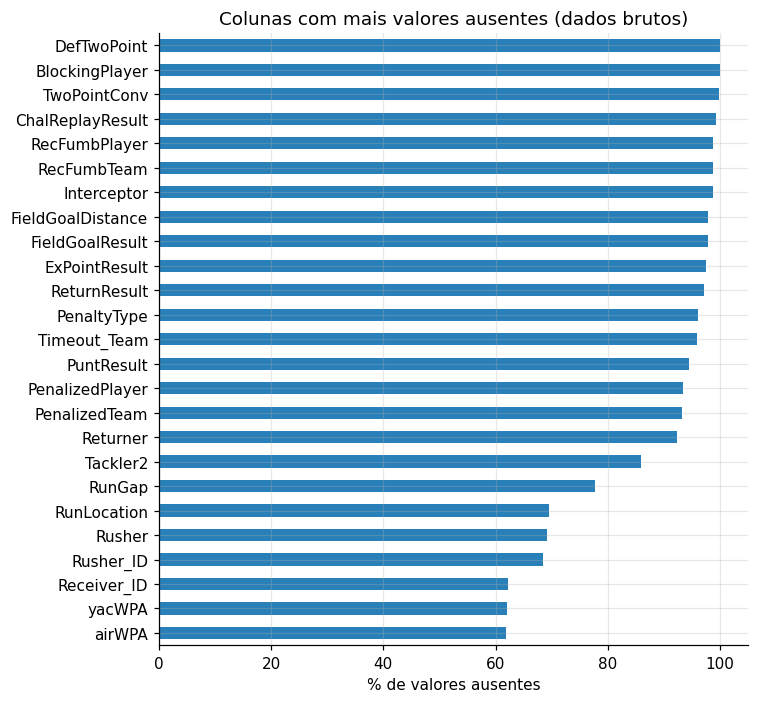

Colunas totalmente completas: 8 de 102
Colunas com mais de 90% de ausentes: 17


In [13]:
# 2.3 Valores ausentes: 25 colunas com maior percentual
aus_top = perfil.sort_values("pct_ausentes", ascending=False).head(25)
ax = aus_top["pct_ausentes"].sort_values().plot.barh(figsize=(7, 6.5), color="#2980b9")
ax.set_xlabel("% de valores ausentes"); ax.set_title("Colunas com mais valores ausentes (dados brutos)")
plt.tight_layout(); plt.show()

print("Colunas totalmente completas:", int((perfil.ausentes == 0).sum()), "de", len(perfil))
print("Colunas com mais de 90% de ausentes:", int((perfil.pct_ausentes > 90).sum()))

In [14]:
# 2.4 Inconsistências de TIPO: colunas texto que misturam tipos Python (ex.: números e strings)
def eh_texto(s):
    """True se a coluna é de texto (object do pandas 2.x ou StringDtype/str do pandas 3.x)."""
    return s.dtype == object or isinstance(s.dtype, pd.StringDtype)

colunas_texto_bruto = [c for c in bruto.columns if eh_texto(bruto[c])]
mistas = {}
for c in colunas_texto_bruto:
    tipos = bruto[c].dropna().map(type).value_counts()
    if len(tipos) > 1:
        mistas[c] = {t.__name__: int(q) for t, q in tipos.items()}

print(f"{len(colunas_texto_bruto)} colunas de texto; {len(mistas)} com tipos Python misturados.")
for c, t in mistas.items():
    print(f"  • {c}: {t}")

37 colunas de texto; 0 com tipos Python misturados.


In [15]:
# 2.5 Inconsistências de CONTEÚDO: espaços nas pontas, textos que "fingem" ser ausência e códigos sentinela
TOKENS_AUSENCIA = {"", "na", "n/a", "nan", "null", "none", "#n/a"}            # seguramente significam "vazio"
TOKENS_REVISAR  = {"?", "-", "--", "unknown", "undefined", "desconhecido"}     # só revisar (podem ser valores reais)

linhas = []
for c in colunas_texto_bruto:
    s = bruto[c].dropna()
    s = s[s.map(lambda v: isinstance(v, str))]
    if s.empty:
        continue
    st = s.str.strip()
    linhas.append({"coluna": c,
                   "espacos_nas_pontas": int((s != st).sum()),
                   "tokens_de_ausencia": int(st.str.lower().isin(TOKENS_AUSENCIA).sum()),
                   "tokens_para_revisar": int(st.str.lower().isin(TOKENS_REVISAR).sum())})
susp = pd.DataFrame(linhas).set_index("coluna")
susp = susp[(susp > 0).any(axis=1)]
print("Colunas de texto com problemas de conteúdo:")
display(susp if len(susp) else pd.DataFrame({"resultado": ["nenhum problema encontrado"]}))

# Códigos sentinela numéricos (valores que parecem "marcadores" de dado faltante)
SENTINELAS = [-999, -9999, 999, 9999]
num_bruto = bruto.select_dtypes("number")
sent = {c: int(num_bruto[c].isin(SENTINELAS).sum()) for c in num_bruto.columns if num_bruto[c].isin(SENTINELAS).any()}
print("Colunas numéricas com valores sentinela", SENTINELAS, "->", sent if sent else "nenhuma")

Colunas de texto com problemas de conteúdo:


,espacos_nas_pontas,tokens_de_ausencia,tokens_para_revisar
coluna,,,
desc,1,0,0


Colunas numéricas com valores sentinela [-999, -9999, 999, 9999] -> {'TimeSecs': 6}


In [16]:
# 2.6 Duplicidade exata (linhas idênticas em todas as colunas)
dup_bruto = int(bruto.duplicated().sum())
print("Linhas duplicadas (idênticas em todas as colunas):", dup_bruto)

Linhas duplicadas (idênticas em todas as colunas): 0


In [17]:
# 2.7 Resumo automático do diagnóstico
md(f"""
### Interpretação do diagnóstico
* O dataset tem **{base['linhas']:,} jogadas** e **{base['colunas']} atributos**, ocupando **{base['memoria_bytes']/MB:,.0f} MiB** na memória e **{base['csv_bytes']/MB:,.0f} MiB** em CSV.
* Distribuição de tipos: {', '.join(f'**{q}** `{t}`' for t, q in tipos_atuais['colunas'].items())}.
* **{int((perfil.pct_ausentes > 90).sum())} colunas têm mais de 90% de ausentes** — são campos de eventos raros (ex.: bloqueio, conversão de 2 pontos) e **não indicam má qualidade**: ausência aqui significa *"o evento não ocorreu"*.
* Colunas de texto com **tipos misturados**: **{len(mistas)}**{' — travam a conversão para tipos eficientes e serão padronizadas na tipificação.' if mistas else ' (com `low_memory=False` o pandas lê cada coluna com tipo uniforme).'}
* Textos com espaços nas pontas / tokens de ausência: **{len(susp)}** coluna(s) afetada(s).
* **Duplicatas exatas: {dup_bruto}.**
* Muitos atributos numéricos estão em `int64`/`float64` ocupando 8 bytes por valor, quando bastariam 1 ou 2 (ex.: `qtr`, `down`, flags 0/1) — **grande oportunidade de otimização**.
""")


### Interpretação do diagnóstico
* O dataset tem **51,429 jogadas** e **102 atributos**, ocupando **103 MiB** na memória e **34 MiB** em CSV.
* Distribuição de tipos: **59** `float64`, **37** `object`, **6** `int64`.
* **17 colunas têm mais de 90% de ausentes** — são campos de eventos raros (ex.: bloqueio, conversão de 2 pontos) e **não indicam má qualidade**: ausência aqui significa *"o evento não ocorreu"*.
* Colunas de texto com **tipos misturados**: **0** (com `low_memory=False` o pandas lê cada coluna com tipo uniforme).
* Textos com espaços nas pontas / tokens de ausência: **1** coluna(s) afetada(s).
* **Duplicatas exatas: 0.**
* Muitos atributos numéricos estão em `int64`/`float64` ocupando 8 bytes por valor, quando bastariam 1 ou 2 (ex.: `qtr`, `down`, flags 0/1) — **grande oportunidade de otimização**.


<a id="3"></a>
## 3. Tipificação

**Objetivo:** dar a cada coluna o tipo que reflete o seu **significado**, de forma **sem perdas** (nenhum valor válido pode mudar).

### 3.1 Saneamento textual (pré-requisito da tipificação)
Antes de converter tipos preciso garantir que o texto esteja limpo, senão uma coluna numérica com um `" "` ou `"N/A"` perdido nunca seria reconhecida como numérica:

| Problema | Decisão | Justificativa |
|---|---|---|
| Espaços no início/fim do texto | `strip()` | Espaço nas pontas cria "falsos" valores distintos (`"NE"` ≠ `"NE "`) sem nenhum significado. |
| Textos como `""`, `"NA"`, `"N/A"`, `"null"`, `"none"` | Converter para ausente (`NaN`) | São formas de escrever "vazio"; deixá-los como texto atrapalha contagens e tipos. |
| `"?"`, `"-"`, `"unknown"` | **Não** converter automaticamente | Podem ser valores reais; só são tratados se a inspeção provar que são ausência. |

In [18]:
# 3.1 Aplicação do saneamento textual em uma CÓPIA de trabalho (df); o `bruto` permanece intacto
df = bruto.copy()

n_espacos_total, n_tokens_total = 0, 0
for c in [c for c in df.columns if eh_texto(df[c])]:
    s = df[c]
    eh_str = s.map(lambda v: isinstance(v, str))
    if not eh_str.any():
        continue
    limpo = s.map(lambda v: v.strip() if isinstance(v, str) else v)           # remove espaços nas pontas
    n_esp = int((eh_str & (s != limpo)).sum())
    tokens = eh_str & limpo.map(lambda v: isinstance(v, str) and v.lower() in TOKENS_AUSENCIA)
    limpo = limpo.mask(tokens, np.nan)                                         # tokens de ausência -> NaN
    if n_esp:        registrar("saneamento", c, n_esp, "espaços nas pontas removidos")
    if tokens.any(): registrar("saneamento", c, tokens.sum(), "texto de ausência convertido em NaN")
    n_espacos_total += n_esp; n_tokens_total += int(tokens.sum())
    df[c] = limpo

print(f"Valores com espaços removidos: {n_espacos_total:,} | tokens convertidos em ausente: {n_tokens_total:,}")

Valores com espaços removidos: 1 | tokens convertidos em ausente: 0


### 3.2 Plano de tipificação (regras)
O plano é **gerado por regras explícitas aplicadas ao conteúdo real de cada coluna** (e não escolhido "no olho"), e depois eu confiro o resultado:

| Se a coluna... | Tipo escolhido | Por quê |
|---|---|---|
| tem só datas no formato `AAAA-MM-DD` (ex.: `Date`) | `datetime64[ns]` | É uma data de calendário; permite filtros e cálculos temporais. |
| tem só relógio `MM:SS` (ex.: `time`) | `timedelta64[ns]` | É um **tempo restante no quarto** (duração), não um texto. |
| tem só valores 0 e 1 (flags como `Touchdown`, `Safety`) | `bool` (ou `boolean` se houver ausentes) | São indicadores verdadeiro/falso; 1 byte em vez de 8. |
| tem só números inteiros | menor inteiro que comporta o intervalo (`int8`…`int64`; `Int8`… se houver ausentes) | Mesmo valor, menos memória. Inteiros com `NaN` ficam em *nullable* `Int*`, que **não transforma 3 em 3.0**. |
| é inteira em texto, mas com zero à esquerda (`"007"`) | mantida como texto | Zero à esquerda indica **código**, não quantidade. |
| tem decimais | `float32` **somente se for exato**, senão `float64` | Reduzir precisão alteraria os dados; só reduzo se a conversão for matematicamente idêntica. |
| é texto com poucos valores distintos (≤ 50% dos valores) | `category` | Times, tipos de jogada, nomes de jogadores se repetem milhares de vezes. |
| é texto quase todo único (ex.: `desc`) | `string` | Texto livre não ganha nada com `category`. |

**Identificadores (`GameID`, `Drive`)** continuam **inteiros**: não faço conta com eles, mas inteiro é mais compacto e ordenável do que texto, e não há zero à esquerda.

In [19]:
# 3.2 Funções que implementam as regras de tipificação
PADRAO_DATA    = re.compile(r"\d{4}-\d{2}-\d{2}")
PADRAO_RELOGIO = re.compile(r"\d{2}:\d{2}")

def menor_inteiro(minimo, maximo, anulavel):
    """Menor tipo inteiro (com sinal) que comporta [minimo, maximo]. 'Int*' (nullable) se houver ausentes."""
    for bits in (8, 16, 32, 64):
        lim = 2 ** (bits - 1)
        if minimo >= -lim and maximo <= lim - 1:
            return ("Int" if anulavel else "int") + str(bits)

def propor_tipo(col, s):
    """Devolve (tipo_alvo, justificativa) a partir do CONTEÚDO real da coluna."""
    nn = s.dropna()
    anulavel = bool(s.isna().any())
    if nn.empty:
        return str(s.dtype), "coluna sem valores: mantida"

    if eh_texto(s):
        so_str = bool(nn.map(lambda v: isinstance(v, str)).all())
        if so_str and nn.map(lambda v: bool(PADRAO_DATA.fullmatch(v))).all():
            return "datetime64[ns]", "todos os valores seguem AAAA-MM-DD: é uma data"
        if so_str and nn.map(lambda v: bool(PADRAO_RELOGIO.fullmatch(v))).all():
            return "timedelta64[ns]", "todos os valores seguem MM:SS: é uma duração (relógio do quarto)"
        conv = pd.to_numeric(nn, errors="coerce")
        zero_esq = so_str and bool(nn.map(lambda v: bool(re.match(r"0\d", v))).any())
        if conv.notna().all() and not zero_esq:
            valores, origem = conv.astype("float64"), "texto com conteúdo 100% numérico"
        else:
            niveis = nn.nunique()
            if niveis / len(nn) <= 0.5:
                return "category", f"texto repetitivo ({niveis:,} níveis para {len(nn):,} valores)"
            return "string", f"texto de alta cardinalidade ({niveis:,} níveis): texto livre"
    else:
        if pd.api.types.is_bool_dtype(s):
            return str(s.dtype), "já é booleano"
        if not pd.api.types.is_numeric_dtype(s):
            return str(s.dtype), "tipo não tratado: mantido"
        valores, origem = nn.astype("float64"), "numérico"

    # ----- ramo numérico -----
    if set(pd.unique(valores)) <= {0, 1}:
        return ("boolean" if anulavel else "bool"), f"{origem}; só contém 0/1: indicador"
    if np.all(np.mod(valores, 1) == 0):
        alvo = menor_inteiro(int(valores.min()), int(valores.max()), anulavel)
        return alvo, f"{origem}; inteiros entre {int(valores.min()):,} e {int(valores.max()):,}"
    if np.array_equal(valores.astype("float32").astype("float64"), valores.to_numpy()):
        return "float32", f"{origem}; decimais exatamente representáveis em 32 bits (sem perda)"
    return "float64", f"{origem}; decimais que exigem 64 bits para não perder precisão"

# Monta o plano para TODAS as colunas
plano = pd.DataFrame(
    [(c, str(df[c].dtype), *propor_tipo(c, df[c])) for c in df.columns],
    columns=["coluna", "tipo_atual", "tipo_proposto", "justificativa"]
).set_index("coluna")

print("Resumo do plano (tipo atual -> tipo proposto):")
display(plano.groupby(["tipo_atual", "tipo_proposto"]).size().rename("colunas").to_frame())

Resumo do plano (tipo atual -> tipo proposto):


colunas
tipo_atual tipo_proposto           
float64    Int16                  3
           Int8                  17
           boolean               17
           float64               22
int64      int32                  1
           int8                   5
object     category              32
           datetime64[ns]         1
           string                 3
           timedelta64[ns]        1

In [20]:
# 3.3 Colunas que vão mudar de tipo, com a justificativa de cada uma
muda = plano[plano.tipo_atual != plano.tipo_proposto]
print(f"{len(muda)} de {len(plano)} colunas mudarão de tipo.")
display(muda)

80 de 102 colunas mudarão de tipo.


,tipo_atual,tipo_proposto,justificativa
coluna,,,
Date,object,datetime64[ns],todos os valores seguem AAAA-MM-DD: é uma data
GameID,int64,int32,"numérico; inteiros entre 2,009,091,000 e 2,010..."
Drive,int64,int8,numérico; inteiros entre 1 e 32
qtr,int64,int8,numérico; inteiros entre 1 e 5
down,float64,Int8,numérico; inteiros entre 1 e 4
time,object,timedelta64[ns],todos os valores seguem MM:SS: é uma duração (...
TimeUnder,int64,int8,numérico; inteiros entre 0 e 15
TimeSecs,float64,Int16,"numérico; inteiros entre -893 e 3,600"
PlayTimeDiff,float64,Int16,numérico; inteiros entre 0 e 234


### 3.3 Aplicação **com auditoria**
Cada conversão é verificada por um teste que compara **os valores antes e depois** (`preservado = True` significa: mesmos valores, mesmas posições de ausentes). Também registro quantos valores viraram ausentes por falha de conversão (esperado: **zero**, pois o plano só propõe conversões que já se mostraram 100% possíveis).

In [21]:
# 3.4 Funções de conversão e de verificação
def converter(col, alvo):
    s = df[col]
    if alvo == "datetime64[ns]":
        return pd.to_datetime(s, format="%Y-%m-%d", errors="coerce").astype("datetime64[ns]")
    if alvo == "timedelta64[ns]":
        txt = s.map(lambda v: "00:" + v if isinstance(v, str) else v)   # "15:00" -> "00:15:00" (mm:ss)
        return pd.to_timedelta(txt, errors="coerce").astype("timedelta64[ns]")
    if alvo == "category":
        if s.dropna().map(lambda v: isinstance(v, str)).all():
            return s.astype("category")
        return s.map(lambda v: v if pd.isna(v) else str(v)).astype("category")   # tipos mistos -> texto uniforme
    if alvo == "string":
        return s.map(lambda v: v if pd.isna(v) else str(v)).astype("string")
    x = pd.to_numeric(s, errors="coerce")
    if alvo == "bool":    return x.astype(bool)
    if alvo == "boolean": return x.astype("boolean")
    return x.astype(alvo)                      # int8..int64, Int8..Int64, float32, float64

def _texto_igual(a, b):
    a, b = a.astype("string"), b.astype("string")
    return bool(((a == b).fillna(False) | (a.isna() & b.isna())).all())

def valores_preservados(antes, depois, alvo):
    """Confere se `depois` contém exatamente os mesmos valores de `antes` (e as mesmas ausências)."""
    if alvo == "datetime64[ns]":
        return _texto_igual(antes, depois.dt.strftime("%Y-%m-%d"))
    if alvo == "timedelta64[ns]":
        tot = depois.dt.total_seconds().round()
        mm, ss = (tot // 60).astype("Int64"), (tot % 60).astype("Int64")
        return _texto_igual(antes, mm.astype("string").str.zfill(2) + ":" + ss.astype("string").str.zfill(2))
    if alvo in ("category", "string"):
        return _texto_igual(antes, depois)
    a = pd.to_numeric(antes, errors="coerce").to_numpy(dtype="float64", na_value=np.nan)
    b = depois.to_numpy(dtype="float64", na_value=np.nan)
    return bool(np.array_equal(a, b, equal_nan=True))

In [22]:
# 3.5 Aplicação das conversões + auditoria linha a linha
auditoria = []
for col, linha in plano.iterrows():
    alvo = linha["tipo_proposto"]
    if alvo == linha["tipo_atual"]:
        continue
    antes = df[col]
    na_antes = int(antes.isna().sum())
    mem_antes = antes.memory_usage(deep=True, index=False)
    try:
        depois = converter(col, alvo)
    except Exception as erro:                      # nunca derruba o notebook: registra e mantém o tipo original
        auditoria.append({"coluna": col, "de": linha["tipo_atual"], "para": alvo, "preservado": False,
                          "novos_ausentes": np.nan, "mem_antes_MiB": mem_antes / MB, "mem_depois_MiB": np.nan,
                          "obs": f"ERRO: {erro}"})
        continue
    ok = valores_preservados(antes, depois, alvo)
    novos_na = int(depois.isna().sum()) - na_antes
    auditoria.append({"coluna": col, "de": linha["tipo_atual"], "para": str(depois.dtype), "preservado": ok,
                      "novos_ausentes": novos_na, "mem_antes_MiB": mem_antes / MB,
                      "mem_depois_MiB": depois.memory_usage(deep=True, index=False) / MB, "obs": ""})
    if ok:                                         # só adota a conversão se comprovadamente sem perdas
        df[col] = depois
        registrar("tipificação", col, df.shape[0], f"{linha['tipo_atual']} -> {depois.dtype}")

auditoria = pd.DataFrame(auditoria).set_index("coluna")
display(auditoria.sort_values("mem_antes_MiB", ascending=False))
md(f"""
**Resultado da auditoria:** {int(auditoria.preservado.sum())} de {len(auditoria)} conversões preservaram 100% dos valores;
**{int(auditoria.novos_ausentes.fillna(0).abs().sum())} valores** viraram ausentes por falha de conversão.
""")

,de,para,preservado,novos_ausentes,mem_antes_MiB,mem_depois_MiB,obs
coluna,,,,,,,
desc,object,string,True,0,6.470,6.470,
Date,object,datetime64[ns],True,0,2.894,0.392,
time,object,timedelta64[ns],True,0,2.648,0.392,
PlayType,object,category,True,0,2.636,0.050,
AwayTeam,object,category,True,0,2.540,0.052,
HomeTeam,object,category,True,0,2.539,0.052,
SideofField,object,category,True,0,2.539,0.052,
DefensiveTeam,object,category,True,0,2.476,0.052,
posteam,object,category,True,0,2.476,0.052,



**Resultado da auditoria:** 80 de 80 conversões preservaram 100% dos valores;
**0 valores** viraram ausentes por falha de conversão.


In [23]:
# 3.6 Antes x depois: tipos e memória
mem_depois_tip = int(df.memory_usage(deep=True).sum())
comp_tipos = pd.concat([bruto.dtypes.astype(str).value_counts().rename("antes"),
                        df.dtypes.astype(str).value_counts().rename("depois")], axis=1).fillna(0).astype(int)
display(comp_tipos)
md(f"**Memória:** {base['memoria_bytes']/MB:,.1f} MiB → **{mem_depois_tip/MB:,.1f} MiB** "
   f"({(1 - mem_depois_tip/base['memoria_bytes'])*100:.1f}% menor), sem alterar nenhum valor válido.")

,antes,depois
float64,59,22
object,37,0
int64,6,0
category,0,32
Int8,0,17
boolean,0,17
int8,0,5
Int16,0,3
string,0,3
datetime64[ns],0,1


**Memória:** 102.9 MiB → **28.1 MiB** (72.7% menor), sem alterar nenhum valor válido.

### Decisões e justificativas da tipificação
* **`Date` → `datetime64`**: é uma data de calendário. Como texto, não permitiria ordenar/filtrar por período com segurança.
* **`time` → `timedelta64`**: representa o *tempo restante no quarto* (`MM:SS`). É uma duração; a coluna `TimeSecs` já traz o tempo corrido em segundos, então mantenho `time` como duração fiel ao original.
* **Flags 0/1 → `bool`/`boolean`**: `Touchdown`, `Safety`, `FirstDown`, `GoalToGo` etc. são sim/não. Quando a flag tem ausentes (a jogada não permite a pergunta), uso `boolean` *nullable*, que guarda `True`, `False` e **ausente** como três estados distintos — convertê-la para `bool` puro obrigaria a escolher `False`, o que **inventaria informação**.
* **Contadores e posições → menor inteiro possível** (`qtr`, `down`, `ydstogo`, placares…): o valor é o mesmo, mas com 1–2 bytes em vez de 8. Onde há ausentes, usei `Int*` *nullable* para **não transformar inteiros em decimais** só por causa do `NaN` (ex.: `down = 3` não vira `3.0`).
* **Texto repetitivo → `category`**: times, tipos de jogada, jogadores e resultados se repetem centenas de milhares de vezes; `category` guarda cada texto uma vez e o resto são códigos curtos.
* **Texto livre (`desc`) → `string`**: quase todo valor é único, `category` não ajudaria.
* **Decimais → `float32` só se exato**: probabilidades e EPA/WPA são, em geral, números de 64 bits que **não** cabem em 32 sem perda; o código testa e mantém `float64` nesses casos. Preferi garantir fidelidade total a ganhar memória à custa de precisão.
* **Colunas com tipos misturados** (números e textos na mesma coluna) foram padronizadas como **texto uniforme** antes de virarem `category`, porque o formato Parquet não aceita tipos misturados na mesma coluna.

<a id="4"></a>
## 4. Tratamento de valores ausentes

**Ponto de partida:** numa base de *jogadas*, um `NaN` quase nunca é "erro de digitação". Uma jogada de *punt* não tem `Passer`; um *kickoff* não tem `down`. Tratar tudo igual (por exemplo, "preencher com a média" ou "apagar colunas com mais de X% de nulos") **destruiria informação ou inventaria dados**.

### 4.1 Método: classificar cada coluna pela *causa* da ausência
Para cada coluna com ausentes calculo, além do percentual, o quanto a ausência é **explicada pelo tipo da jogada (`PlayType`)**:

* **pureza** = proporção de linhas em que "ausente/presente" é previsível sabendo só o `PlayType`;
* **explicada** = quanto da incerteza sobre estar ausente o `PlayType` elimina (1 = totalmente determinístico, 0 = nada explica).

| Classe | Critério | Significado | Estratégia |
|---|---|---|---|
| **vazia** | 100% ausente | não traz informação | remover a coluna |
| **evento raro** | ≥ 90% ausente | *"o evento não ocorreu"* | **manter `NaN`** |
| **estrutural** | pureza ≥ 0,95 e explicada ≥ 0,80 | *"não se aplica a esse tipo de jogada"* | **manter `NaN`** |
| **baixa incidência** | < 5% ausente, sem explicação estrutural | possível falha de registro | investigar; recuperar por regra ou imputar de forma conservadora |
| **parcial** | demais casos | ausência sem causa clara | **manter `NaN`** e documentar |

In [24]:
# 4.1 Diagnóstico das ausências por coluna (após tipificação)
def tabela_ausentes(d):
    n = len(d)
    ref = d["PlayType"].astype("object").fillna("<<sem PlayType>>") if "PlayType" in d.columns else None
    linhas = []
    for c in d.columns:
        m = d[c].isna()
        k = int(m.sum())
        if k == 0:
            continue
        p_aus = k / n
        pureza, explicada = np.nan, np.nan
        if ref is not None and k < n:
            g = m.groupby(ref)
            p, t = g.mean(), g.size()
            pureza = float((np.maximum(p, 1 - p) * t).sum() / t.sum())
            explicada = float(np.clip(1 - (1 - pureza) / min(p_aus, 1 - p_aus), 0, 1))
        if   k == n:                                                    classe = "vazia"
        elif p_aus >= 0.90:                                             classe = "evento raro"
        elif pd.notna(pureza) and pureza >= 0.95 and explicada >= 0.80: classe = "estrutural"
        elif p_aus < 0.05:                                              classe = "baixa incidência"
        else:                                                           classe = "parcial"
        linhas.append({"coluna": c, "dtype": str(d[c].dtype), "ausentes": k, "pct": p_aus * 100,
                       "pureza_PlayType": pureza, "explicada_PlayType": explicada, "classe": classe})
    return pd.DataFrame(linhas).set_index("coluna").sort_values("pct", ascending=False)

tab_aus = tabela_ausentes(df)
display(tab_aus)
display(tab_aus.groupby("classe").agg(colunas=("pct", "size"), pct_medio=("pct", "mean")))

,dtype,ausentes,pct,pureza_PlayType,explicada_PlayType,classe
coluna,,,,,,
DefTwoPoint,float64,51429,100.000,NaN,NaN,vazia
BlockingPlayer,string,51421,99.984,1.000,0.000,evento raro
TwoPointConv,category,51368,99.881,0.999,0.000,evento raro
ChalReplayResult,category,51082,99.325,0.993,0.000,evento raro
RecFumbPlayer,string,50801,98.779,0.988,0.000,evento raro
RecFumbTeam,category,50801,98.779,0.988,0.000,evento raro
Interceptor,category,50785,98.748,0.987,0.000,evento raro
FieldGoalDistance,Int8,50361,97.923,1.000,0.999,evento raro
FieldGoalResult,category,50352,97.906,1.000,0.991,evento raro


,colunas,pct_medio
classe,,
baixa incidência,17,0.174
estrutural,56,17.293
evento raro,16,96.951
parcial,4,52.374
vazia,1,100.000


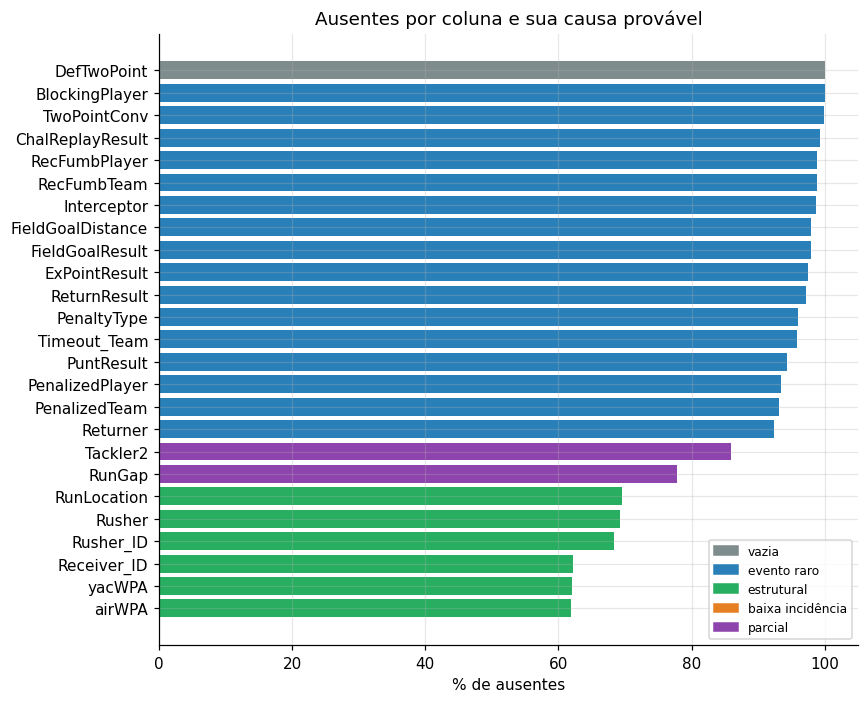

In [25]:
# 4.2 Visualização: percentual de ausentes por coluna, colorido pela classe
cores = {"vazia": "#7f8c8d", "evento raro": "#2980b9", "estrutural": "#27ae60",
         "baixa incidência": "#e67e22", "parcial": "#8e44ad"}
top = tab_aus.head(25).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(top.index, top["pct"], color=[cores[c] for c in top["classe"]])
ax.set_xlabel("% de ausentes"); ax.set_title("Ausentes por coluna e sua causa provável")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=v) for v in cores.values()], labels=list(cores), loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

### 4.2 Estratégias aplicadas
1. **Colunas vazias (100%)**: removidas, pois não carregam informação. *(Se não houver nenhuma, nada é removido.)*
2. **Evento raro e estrutural → mantidos como `NaN`.** Preencher `Passer` com "desconhecido" numa jogada de corrida criaria um jogador inexistente; preencher `down` num kickoff criaria uma descida que não aconteceu. Manter `NaN` **preserva o significado** e o Parquet armazena ausentes quase sem custo.
3. **Recuperação determinística (melhor que imputar):** se um valor ausente pode ser **calculado com exatidão** a partir de outras colunas (ex.: `ScoreDiff = PosTeamScore − DefTeamScore`), ele é recuperado — mas **só depois de confirmar que a regra vale nos dados** (taxa de divergência < 1%).
4. **Imputação simples (mediana + sinalizador) — apenas em último caso:** só para colunas de **baixa incidência (≤ 2%)**, numéricas, **medidas** (não saídas de modelo como EPA/WPA/probabilidades, que são estimativas e não devem ser "estimadas de novo"). A **mediana** é escolhida por ser robusta a valores extremos (jardas e placares são assimétricos). Cada imputação cria uma coluna `*_imputado` para que ninguém confunda dado observado com dado estimado.
5. **Não uso imputação múltipla**: exige hipótese sobre o mecanismo de ausência (MCAR/MAR/MNAR) e as ausências aqui são, na maioria, **estruturais**, não aleatórias; a técnica geraria valores que nunca existiram.
6. **Não removo linhas** por causa de ausentes: apagar jogadas só porque falta um atributo inaplicável eliminaria quase toda a base.

In [26]:
# 4.3 (1) Remoção de colunas 100% vazias
vazias = tab_aus.index[tab_aus["classe"] == "vazia"].tolist()
if vazias:
    df = df.drop(columns=vazias)
    for c in vazias: registrar("ausentes", c, df.shape[0], "coluna 100% vazia removida")
print("Colunas vazias removidas:", vazias if vazias else "nenhuma")

# 4.4 (3) Recuperação determinística: ScoreDiff = PosTeamScore - DefTeamScore
if {"ScoreDiff", "PosTeamScore", "DefTeamScore"} <= set(df.columns):
    f = lambda c: pd.Series(df[c].to_numpy(dtype="float64", na_value=np.nan), index=df.index)
    esperado = f("PosTeamScore") - f("DefTeamScore")
    comparavel = esperado.notna() & f("ScoreDiff").notna()
    diverg = int((comparavel & (f("ScoreDiff") != esperado)).sum())
    taxa = diverg / max(int(comparavel.sum()), 1)
    recuperaveis = df["ScoreDiff"].isna() & esperado.notna()
    print(f"ScoreDiff: {diverg:,} divergências em {int(comparavel.sum()):,} linhas comparáveis ({taxa:.3%}); recuperáveis: {int(recuperaveis.sum()):,}")
    if taxa < 0.01 and recuperaveis.any():
        df.loc[recuperaveis, "ScoreDiff"] = esperado[recuperaveis].round().astype(df["ScoreDiff"].dtype)
        registrar("ausentes", "ScoreDiff", recuperaveis.sum(), "recuperado por PosTeamScore - DefTeamScore")
        print(f"  -> {int(recuperaveis.sum()):,} valores recuperados por cálculo exato.")
    else:
        print("  -> regra não confirmada (ou nada a recuperar): nenhuma alteração.")
else:
    print("ScoreDiff/PosTeamScore/DefTeamScore ausentes no dataset: etapa pulada.")

Colunas vazias removidas: ['DefTwoPoint']
ScoreDiff: 0 divergências em 47,800 linhas comparáveis (0.000%); recuperáveis: 0
  -> regra não confirmada (ou nada a recuperar): nenhuma alteração.


In [27]:
# 4.5 (4) Imputação simples conservadora (mediana + sinalizador) — somente colunas elegíveis
tab_aus = tabela_ausentes(df)                      # recalcula após as etapas anteriores
SAIDAS_DE_MODELO = ("EPA", "WPA", "WP", "Prob", "ExpPts", "Win_Prob")

candidatas = [c for c in tab_aus.index[(tab_aus["classe"] == "baixa incidência") & (tab_aus["pct"] <= 2)]
              if pd.api.types.is_numeric_dtype(df[c]) and not pd.api.types.is_bool_dtype(df[c])
              and not any(k in c for k in SAIDAS_DE_MODELO)]

imputadas = []
for c in candidatas:
    mascara = df[c].isna()
    mediana = df[c].median()
    if pd.api.types.is_integer_dtype(df[c]):
        mediana = int(round(mediana))
    df[c] = df[c].fillna(mediana)
    df[f"{c}_imputado"] = mascara                   # sinalizador: True = valor estimado
    registrar("ausentes", c, mascara.sum(), f"imputado com mediana ({mediana})")
    imputadas.append((c, int(mascara.sum()), mediana))

print("Colunas elegíveis para imputação:", [c for c, _, _ in imputadas] if imputadas else "nenhuma")
for c, q, m in imputadas:
    print(f"  • {c}: {q:,} valores preenchidos com a mediana {m}")

Colunas elegíveis para imputação: ['yrdln', 'yrdline100', 'PlayTimeDiff', 'TimeSecs']
  • yrdln: 107 valores preenchidos com a mediana 30
  • yrdline100: 107 valores preenchidos com a mediana 49
  • PlayTimeDiff: 68 valores preenchidos com a mediana 18
  • TimeSecs: 34 valores preenchidos com a mediana 1800


In [28]:
# 4.6 Balanço do tratamento de ausentes
tab_final_aus = tabela_ausentes(df)
resumo_classes = tab_final_aus["classe"].value_counts()
md(f"""
### Balanço (ausentes)
* Colunas ainda com ausentes: **{len(tab_final_aus)}** de {df.shape[1]} — por classe: {', '.join(f'**{q}** {c}' for c, q in resumo_classes.items())}.
* Ausentes mantidos **por serem informação** (evento raro + estrutural + parciais): **{int(tab_final_aus['ausentes'].sum()):,}** células.
* Valores recuperados/imputados: **{sum(l['quantidade'] for l in log if l['etapa']=='ausentes' and ('recuperado' in l['detalhe'] or 'imputado' in l['detalhe'])):,}**
  (cada um rastreável no `log`; imputações têm sinalizador `*_imputado`).
""")


### Balanço (ausentes)
* Colunas ainda com ausentes: **89** de 105 — por classe: **56** estrutural, **16** evento raro, **13** baixa incidência, **4** parcial.
* Ausentes mantidos **por serem informação** (evento raro + estrutural + parciais): **1,404,752** células.
* Valores recuperados/imputados: **316**
  (cada um rastreável no `log`; imputações têm sinalizador `*_imputado`).


### Decisões e justificativas (ausentes)
* **A maior parte dos ausentes foi mantida de propósito.** Nas classes *evento raro* e *estrutural*, `NaN` significa "não se aplica" ou "não ocorreu". Substituir por média, moda ou "desconhecido" **inventaria fatos** (um passador numa corrida, uma descida num kickoff) e distorceria médias e contagens futuras.
* **Não usei uma regra fixa do tipo "mais de X% de nulo → apagar coluna".** Colunas como `BlockingPlayer` ou `DefTwoPoint` são quase todas vazias justamente porque o evento é raríssimo; apagá-las faria perder o registro desses eventos.
* **Prefiro recuperar a imputar:** quando um valor pode ser calculado de outras colunas (`ScoreDiff`), o resultado é **exato**, não uma estimativa.
* **Mediana, e não média**, nas poucas imputações elegíveis: robusta a extremos (um *touchdown* de 99 jardas não deve puxar o valor típico).
* **Saídas de modelo (EPA, WPA, probabilidades) nunca são imputadas**: já são estimativas; preenchê-las seria estimar uma estimativa sem base.
* **Rastreabilidade:** toda imputação tem sinalizador próprio e entrada no `log`, então qualquer análise futura pode ignorar os valores estimados.
* **Limitação:** a classificação *estrutural* usa `PlayType` como explicação. Ela confirma que a ausência é previsível pelo tipo de jogada, mas **não prova** o mecanismo (MCAR/MAR/MNAR); por isso a decisão conservadora de não preencher.

<a id="5"></a>
## 5. Limpeza dos dados

Quatro frentes: **(1) duplicidades**, **(2) categorias escritas de formas diferentes**, **(3) valores fora do domínio** e **(4) consistência entre colunas / valores extremos**.

### 5.1 Duplicidades
* **Duplicata exata** (todas as colunas iguais) é redundância pura → **remover**.
* **Repetição de `GameID` não é duplicidade**: um jogo tem ~150 jogadas.
* Para uma **chave natural** da jogada uso `GameID + Drive + qtr + TimeSecs + desc`. Se duas linhas compartilham a chave mas **diferem em algum outro campo**, **não** apago nenhuma: pode ser correção/anotação distinta e a decisão exige julgamento humano. Apenas reporto.

In [29]:
# 5.1 Duplicidades: exatas (remover) e por chave natural (apenas reportar)
n_antes = len(df)
dup_exatas = int(df.duplicated().sum())
if dup_exatas:
    exemplo = df[df.duplicated(keep=False)].head(6)
    print("Exemplo de linhas duplicadas:"); display(exemplo)
    df = df.drop_duplicates().reset_index(drop=True)
    registrar("limpeza", "(linhas)", dup_exatas, "duplicatas exatas removidas")
print(f"Duplicatas exatas removidas: {dup_exatas}  ({n_antes:,} -> {len(df):,} linhas)")

chave = [c for c in ["GameID", "Drive", "qtr", "TimeSecs", "desc"] if c in df.columns]
dup_chave = df.duplicated(chave, keep=False)
print(f"Linhas que compartilham a chave natural {chave} após remover exatas: {int(dup_chave.sum())}")
if dup_chave.any():
    display(df[dup_chave].sort_values(chave).head(10))

Duplicatas exatas removidas: 0  (51,429 -> 51,429 linhas)
Linhas que compartilham a chave natural ['GameID', 'Drive', 'qtr', 'TimeSecs', 'desc'] após remover exatas: 8


,Date,GameID,Drive,qtr,down,time,TimeUnder,TimeSecs,PlayTimeDiff,SideofField,yrdln,yrdline100,ydstogo,ydsnet,GoalToGo,FirstDown,posteam,DefensiveTeam,desc,PlayAttempted,Yards.Gained,sp,Touchdown,ExPointResult,TwoPointConv,Safety,Onsidekick,PuntResult,PlayType,Passer,Passer_ID,PassAttempt,PassOutcome,PassLength,AirYards,YardsAfterCatch,QBHit,PassLocation,InterceptionThrown,Interceptor,Rusher,Rusher_ID,RushAttempt,RunLocation,RunGap,Receiver,Receiver_ID,Reception,ReturnResult,Returner,BlockingPlayer,Tackler1,Tackler2,FieldGoalResult,FieldGoalDistance,Fumble,RecFumbTeam,RecFumbPlayer,Sack,Challenge.Replay,ChalReplayResult,Accepted.Penalty,PenalizedTeam,PenaltyType,PenalizedPlayer,Penalty.Yards,PosTeamScore,DefTeamScore,ScoreDiff,AbsScoreDiff,HomeTeam,AwayTeam,Timeout_Indicator,Timeout_Team,posteam_timeouts_pre,HomeTimeouts_Remaining_Pre,AwayTimeouts_Remaining_Pre,HomeTimeouts_Remaining_Post,AwayTimeouts_Remaining_Post,No_Score_Prob,Opp_Field_Goal_Prob,Opp_Safety_Prob,Opp_Touchdown_Prob,Field_Goal_Prob,Safety_Prob,Touchdown_Prob,ExPoint_Prob,TwoPoint_Prob,ExpPts,EPA,airEPA,yacEPA,Home_WP_pre,Away_WP_pre,Home_WP_post,Away_WP_post,Win_Prob,WPA,airWPA,yacWPA,Season,yrdln_imputado,yrdline100_imputado,PlayTimeDiff_imputado,TimeSecs_imputado
436,2009-09-13,2009091307,14,2,<NA>,0 days 00:01:03,2,1863,7,NO,30,30,0,0,False,False,NaN,NaN,Timeout #2 by NO at 01:03.,True,0,False,False,NaN,NaN,False,False,NaN,Timeout,NaN,NaN,False,NaN,NaN,0,0,False,NaN,False,NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,False,NaN,NaN,<NA>,NaN,NaN,NaN,<NA>,False,NaN,<NA>,False,False,NaN,False,NaN,NaN,NaN,0,<NA>,<NA>,<NA>,<NA>,NO,DET,True,NO,1,2,1,1,1,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000,NaN,NaN,2009,False,False,False,False
438,2009-09-13,2009091307,14,2,<NA>,0 days 00:01:03,2,1863,8,NO,30,30,0,0,False,<NA>,NaN,NaN,Timeout #2 by NO at 01:03.,True,0,False,False,NaN,NaN,False,False,NaN,Timeout,NaN,NaN,False,NaN,NaN,0,0,False,NaN,False,NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,False,NaN,NaN,<NA>,NaN,NaN,NaN,<NA>,False,NaN,<NA>,False,False,NaN,False,NaN,NaN,NaN,0,<NA>,<NA>,<NA>,<NA>,NO,DET,True,NO,1,1,1,0,1,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000,NaN,NaN,2009,False,False,False,False
27343,2009-11-22,2009112212,23,4,2,0 days 00:00:21,1,21,2,CIN,15,15,8,2,False,False,OAK,CIN,(:21) B.Gradkowski kneels to CIN 15 for no gain.,True,0,False,False,NaN,NaN,False,False,NaN,QB Kneel,NaN,NaN,False,NaN,NaN,0,0,False,NaN,False,NaN,NaN,00-0024408,False,NaN,NaN,NaN,NaN,False,NaN,NaN,<NA>,NaN,NaN,NaN,<NA>,False,NaN,<NA>,False,False,NaN,False,NaN,NaN,NaN,0,17,17,0,0,OAK,CIN,False,NaN,1,1,2,1,2,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,NaN,NaN,0.507,0.493,0.534,0.466,0.507,0.027,NaN,NaN,2009,False,False,False,False
27345,2009-11-22,2009112212,23,4,3,0 days 00:00:21,1,21,0,CIN,15,15,8,2,False,False,OAK,CIN,(:21) B.Gradkowski kneels to CIN 15 for no gain.,True,0,False,False,NaN,NaN,False,False,NaN,QB Kneel,NaN,NaN,False,NaN,NaN,0,0,False,NaN,False,NaN,NaN,00-0024408,False,NaN,NaN,NaN,NaN,False,NaN,NaN,<NA>,NaN,NaN,NaN,<NA>,False,NaN,<NA>,False,False,NaN,False,NaN,NaN,NaN,0,17,17,0,0,OAK,CIN,False,NaN,1,1,1,1,1,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,NaN,NaN,0.534,0.466,0.971,0.029,0.534,0.437,NaN,NaN,2009,False,False,False,False
41659,2009-12-27,2009122713,19,4,<NA>,0 days 00:05:02,6,302,6,DAL,29,29,0,22,False,False,NaN,NaN,Timeout #2 by WAS at 05:02.,True,0,False,False,NaN,NaN,False,False,NaN,Timeout,NaN,NaN,False,NaN,NaN,0,0,False,NaN,False,NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,False,NaN,NaN,<NA>,NaN,NaN,NaN,<NA>,False,NaN,<NA>,False,False,NaN,False,NaN,NaN,NaN,0,<NA>,<NA>,<NA>,<NA>,WAS,DAL,True,WAS,3,2,3,1,3,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000,NaN,NaN,2009,False,False,False,False
41660,2009-12-27,2009122713,19,4,<NA>,0 days 00:05:02,6,302,0,NaN,30,49,0,22,<NA>,False,NaN,NaN,

### 5.2 Categorias inconsistentes
Procuro valores que **só diferem por caixa alta/baixa ou espaços internos** (`"NE"`, `"ne"`, `"N E"`). Eles são o **mesmo valor escrito de formas diferentes** e devem ser unificados na forma mais frequente.

**O que deliberadamente NÃO unifico:** códigos de times como `SD`→`LAC`, `STL`→`LA` ou `JAC`/`JAX`. Em 2009–2017 essas franquias de fato mudaram de cidade/nome; o código **histórico correto da época** deve ser preservado. Unificá-los apagaria informação real.

In [30]:
# 5.2 Categorias que colidem após normalização (caixa + espaços), com correção pela forma mais frequente
def normalizar(v): return " ".join(str(v).split()).casefold()

total_unificados = 0
colunas_cat = [c for c in df.columns if (isinstance(df[c].dtype, pd.CategoricalDtype) or eh_texto(df[c])) and c != "desc"]
for c in colunas_cat:
    s = df[c].astype("object")
    freq = s.value_counts()
    if freq.empty:
        continue
    grupos = {}
    for valor in freq.index:
        grupos.setdefault(normalizar(valor), []).append(valor)
    colisoes = {k: v for k, v in grupos.items() if len(v) > 1}
    if colisoes:
        mapa = {alt: max(v, key=lambda x: freq[x]) for v in colisoes.values() for alt in v}
        qtd = int(s.isin([a for a, b in mapa.items() if a != b]).sum())
        print(f"{c}: {colisoes}")
        s = s.replace({a: b for a, b in mapa.items() if a != b})
        df[c] = s.astype("category") if isinstance(df[c].dtype, pd.CategoricalDtype) else s.astype(df[c].dtype)
        registrar("limpeza", c, qtd, "variações de caixa/espaços unificadas")
        total_unificados += qtd
print("Total de valores unificados:", total_unificados if total_unificados else "nenhum (categorias já consistentes)")

Total de valores unificados: nenhum (categorias já consistentes)


### 5.3 Valores fora do domínio
Cada regra vem do **significado** do atributo. Diferencio dois níveis:
* **Regra forte** (impossível no mundo real, ex.: probabilidade > 1, quarto 9): o valor vira `NaN` e é contabilizado — não invento um substituto.
* **Regra de alerta** (improvável, mas possível): apenas **reporto**, sem alterar. Por exemplo `ydstogo` ou `TimeSecs` têm limites que dependem de convenções do dataset; alterá-los sem certeza *criaria* erros.

In [31]:
# 5.3 Regras de domínio: (coluna, mínimo, máximo, forte?)
colunas_prob = [c for c in df.columns if "Prob" in c or c.startswith(("Home_WP", "Away_WP")) or c == "Win_Prob"]
REGRAS = ([("qtr", 1, 5, True),            # 4 quartos + prorrogação
           ("down", 1, 4, True),
           ("Season", 2009, 2017, True),   # recorte do dataset
           ("yrdline100", 0, 100, True),
           ("PosTeamScore", 0, None, True), ("DefTeamScore", 0, None, True),
           ("ydstogo", 0, 99, False), ("TimeSecs", -900, 3600, False), ("FieldGoalDistance", 0, 90, False)]
          + [(c, 0, 1, True) for c in colunas_prob])

def para_anulavel(s):
    """Garante um tipo que aceita ausente (int8 -> Int8) antes de anular valores inválidos."""
    if pd.api.types.is_integer_dtype(s) and not isinstance(s.dtype, pd.api.extensions.ExtensionDtype):
        return s.astype(str(s.dtype).replace("int", "Int"))
    return s

resultado_regras = []
for c, lo, hi, forte in REGRAS:
    if c not in df.columns or not pd.api.types.is_numeric_dtype(df[c]):
        continue
    s = df[c]
    viol = pd.Series(False, index=df.index)
    if lo is not None: viol |= (s < lo).fillna(False).astype(bool)
    if hi is not None: viol |= (s > hi).fillna(False).astype(bool)
    q = int(viol.sum())
    acao = "apenas reportado" if not forte else ("nenhum erro" if q == 0 else "convertido em ausente")
    if forte and q:
        df[c] = para_anulavel(df[c])
        df.loc[viol, c] = pd.NA if str(df[c].dtype).startswith(("Int", "boolean")) else np.nan
        registrar("limpeza", c, q, f"fora do domínio [{lo}, {hi}] -> ausente")
    resultado_regras.append({"coluna": c, "regra": f"{lo} ≤ valor ≤ {hi}", "tipo": "forte" if forte else "alerta",
                             "violações": q, "ação": acao})
regras_df = pd.DataFrame(resultado_regras)
display(regras_df)

,coluna,regra,tipo,violações,ação
0,qtr,1 ≤ valor ≤ 5,forte,0,nenhum erro
1,down,1 ≤ valor ≤ 4,forte,0,nenhum erro
2,Season,2009 ≤ valor ≤ 2017,forte,0,nenhum erro
3,yrdline100,0 ≤ valor ≤ 100,forte,0,nenhum erro
4,PosTeamScore,0 ≤ valor ≤ None,forte,0,nenhum erro
5,DefTeamScore,0 ≤ valor ≤ None,forte,0,nenhum erro
6,ydstogo,0 ≤ valor ≤ 99,alerta,0,apenas reportado
7,TimeSecs,-900 ≤ valor ≤ 3600,alerta,0,apenas reportado
8,FieldGoalDistance,0 ≤ valor ≤ 90,alerta,0,apenas reportado
9,No_Score_Prob,0 ≤ valor ≤ 1,forte,0,nenhum erro


### 5.4 Consistência entre colunas e valores extremos
* `Season` deve coincidir com a data: a temporada começa em setembro e termina em fevereiro do ano seguinte (jogos de janeiro/fevereiro pertencem à temporada do ano anterior).
* `posteam` (time com a posse) precisa ser um dos dois times da partida (`HomeTeam` ou `AwayTeam`), e diferente de `DefensiveTeam`.
* **Valores extremos (outliers)** são avaliados pelo contexto do esporte: um ganho de 99 jardas é raro, mas **legítimo** (touchdown de longa distância). Por isso **reporto e não removo** extremos estatísticos; só remove-se o que viola uma regra de domínio.

In [32]:
# 5.4 Verificações cruzadas (apenas reportam; não alteram dados)
if {"Season", "Date"} <= set(df.columns) and pd.api.types.is_datetime64_any_dtype(df["Date"]):
    esperado = np.where(df["Date"].dt.month >= 3, df["Date"].dt.year, df["Date"].dt.year - 1)
    inc = int((df["Season"].to_numpy(dtype="float64", na_value=np.nan) != esperado).sum())
    print(f"Season x Date: {inc:,} linhas inconsistentes")

if {"posteam", "HomeTeam", "AwayTeam"} <= set(df.columns):
    p, h, a = (df[c].astype("object") for c in ("posteam", "HomeTeam", "AwayTeam"))
    fora = int((p.notna() & (p != h) & (p != a)).sum())
    print(f"posteam fora de {{HomeTeam, AwayTeam}}: {fora:,} linhas")
if {"posteam", "DefensiveTeam"} <= set(df.columns):
    igual = int((df["posteam"].astype("object") == df["DefensiveTeam"].astype("object")).sum())
    print(f"posteam == DefensiveTeam: {igual:,} linhas")

# Valores extremos: IQR (alerta, sem remoção)
numericas = [c for c in df.columns if pd.api.types.is_numeric_dtype(df[c]) and not pd.api.types.is_bool_dtype(df[c])
             and df[c].nunique() > 10]
ext = []
for c in numericas:
    x = pd.Series(df[c].to_numpy(dtype="float64", na_value=np.nan)).dropna()
    q1, q3 = x.quantile([.25, .75]); iqr = q3 - q1
    n_ext = int(((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).sum()) if iqr > 0 else 0
    ext.append({"coluna": c, "min": x.min(), "p01": x.quantile(.01), "mediana": x.median(),
                "p99": x.quantile(.99), "max": x.max(), "extremos_IQR": n_ext, "pct_extremos": n_ext / len(x) * 100})
display(pd.DataFrame(ext).set_index("coluna").sort_values("pct_extremos", ascending=False).head(12))

Season x Date: 1 linhas inconsistentes
posteam fora de {HomeTeam, AwayTeam}: 1 linhas
posteam == DefensiveTeam: 0 linhas


,min,p01,mediana,p99,max,extremos_IQR,pct_extremos
coluna,,,,,,,
yacWPA,-0.948,-0.212,0.000,0.132,0.915,4069,20.809
GameID,"2,009,091,000.000","2,009,091,301.000","2,009,112,202.000","2,010,092,605.000","2,010,092,609.000",9549,18.567
AirYards,-52.000,-5.000,0.000,36.000,65.000,8414,16.361
yacEPA,-14.000,-6.964,0.000,3.920,9.060,3043,15.538
No_Score_Prob,0.000,0.000,0.024,0.770,1.000,5400,10.504
WPA,-0.997,-0.117,-0.000,0.124,0.970,5237,10.341
EPA,-11.523,-4.441,-0.002,3.850,9.273,4030,7.843
ScoreDiff,-59.000,-31.000,0.000,28.000,59.000,3196,6.652
Yards.Gained,-36.000,-8.000,2.000,42.000,99.000,3375,6.563


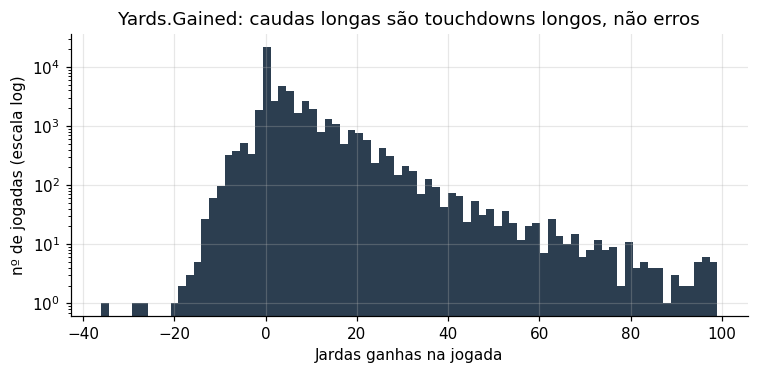

In [33]:
# Visual: o que parece "outlier" em Yards.Gained é jogo legítimo
if "Yards.Gained" in df.columns:
    y = pd.Series(df["Yards.Gained"].to_numpy(dtype="float64", na_value=np.nan)).dropna()
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.hist(y, bins=80, color="#2c3e50"); ax.set_yscale("log")
    ax.set_xlabel("Jardas ganhas na jogada"); ax.set_ylabel("nº de jogadas (escala log)")
    ax.set_title("Yards.Gained: caudas longas são touchdowns longos, não erros")
    plt.tight_layout(); plt.show()

In [34]:
# 5.5 Balanço da limpeza
log_df = pd.DataFrame(log)
resumo_limpeza = log_df[log_df.etapa == "limpeza"]
display(resumo_limpeza if len(resumo_limpeza) else pd.DataFrame({"resultado": ["nenhuma correção foi necessária"]}))
md(f"""
### Balanço (limpeza)
* **Linhas:** {base['linhas']:,} → **{len(df):,}** ({base['linhas'] - len(df)} duplicatas exatas removidas).
* **Categorias unificadas:** {total_unificados} valores · **valores fora do domínio anulados:** {int(resumo_limpeza[resumo_limpeza.detalhe.str.contains('domínio')].quantidade.sum()) if len(resumo_limpeza) else 0}.
* Extremos estatísticos foram **mantidos** (são jogadas reais); só se altera o que é impossível pelas regras do jogo.
""")

,resultado
0,nenhuma correção foi necessária



### Balanço (limpeza)
* **Linhas:** 51,429 → **51,429** (0 duplicatas exatas removidas).
* **Categorias unificadas:** 0 valores · **valores fora do domínio anulados:** 0.
* Extremos estatísticos foram **mantidos** (são jogadas reais); só se altera o que é impossível pelas regras do jogo.


### Decisões e justificativas (limpeza)
* **Só removi duplicatas exatas.** Linhas que compartilham a chave natural mas diferem em algum campo foram **apenas reportadas**: apagar a "errada" exigiria saber qual é a correta.
* **Valores impossíveis viram ausentes, não "corrigidos"**: não há como saber o valor verdadeiro de uma probabilidade 1,7; um `NaN` honesto é melhor que um palpite.
* **Regras de alerta não alteram dados**: restrições como `ydstogo` máximo dependem de convenções que eu não consigo confirmar só pelos dados.
* **Franquias que mudaram de cidade não foram unificadas** (ex.: `SD`/`LAC`): cada código é correto para a sua época.
* **Outliers mantidos:** em futebol americano, jogadas de 80–99 jardas são raras mas reais. Removê-las enviesaria análises sobre jogadas explosivas.

<a id="6"></a>
## 6. Otimização de memória
Antes de gravar, comparo o consumo de memória do DataFrame **bruto** com o **tratado**, agrupando por tipo de dado para ver *de onde veio* a economia.

,antes_MiB,depois_MiB
object,77.425,0.000
float64,23.150,8.240
int64,2.354,0.000
Int16,0.000,0.441
Int8,0.000,1.668
bool,0.000,0.196
boolean,0.000,1.668
category,0.000,2.539
datetime64[ns],0.000,0.392
int32,0.000,0.196


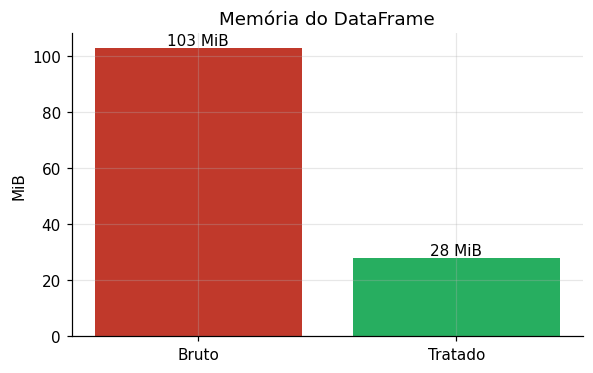

**Memória:** 102.9 MiB → **27.9 MiB** (redução de **72.9%**).

In [35]:
mem_final = int(df.memory_usage(deep=True).sum())
m_antes  = bruto.memory_usage(deep=True, index=False).groupby(bruto.dtypes.astype(str)).sum() / MB
m_depois = df.memory_usage(deep=True, index=False).groupby(df.dtypes.astype(str)).sum() / MB
comp_mem = pd.concat([m_antes.rename("antes_MiB"), m_depois.rename("depois_MiB")], axis=1).fillna(0)
display(comp_mem.sort_values("antes_MiB", ascending=False))

fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.bar(["Bruto", "Tratado"], [base["memoria_bytes"] / MB, mem_final / MB], color=["#c0392b", "#27ae60"])
for i, v in enumerate([base["memoria_bytes"] / MB, mem_final / MB]): ax.text(i, v, f"{v:,.0f} MiB", ha="center", va="bottom")
ax.set_ylabel("MiB"); ax.set_title("Memória do DataFrame")
plt.tight_layout(); plt.show()
md(f"**Memória:** {base['memoria_bytes']/MB:,.1f} MiB → **{mem_final/MB:,.1f} MiB** (redução de **{(1-mem_final/base['memoria_bytes'])*100:.1f}%**).")

<a id="7"></a>
## 7. Armazenamento em Parquet

**Por que o Parquet reduz tamanho?** É um formato **colunar**: valores da mesma coluna ficam juntos, o que permite (1) **codificação por dicionário** (texto repetido guardado uma vez), (2) **codificação por runs** (valores iguais seguidos) e (3) **compressão** muito mais eficaz do que num CSV, que repete cada número como texto.

### Comparação justa
Para não confundir *efeito da limpeza* com *efeito do formato*, comparo quatro arquivos:
1. **CSV original** (referência);
2. **Parquet dos dados brutos**, sem nenhum tratamento (mostra o ganho só do formato);
3. **Parquet dos dados tratados** com compressão padrão (`snappy`);
4. **Parquet dos dados tratados com a melhor configuração** encontrada (desafio de otimização).

### Experimentos de compressão (sem perder nenhum dado)
Todos os testes são **sem perdas**: só mudam o *codec*, o *nível* e a *organização interna* do arquivo — nunca os valores. Testo `snappy` (rápido), `gzip`, `brotli` e `zstd` (níveis 3 e 19), tamanhos de *row group*, página v2 e `BYTE_STREAM_SPLIT` para colunas decimais (que costuma melhorar a compressão de `float`). **A ordem das linhas é mantida** (reordenar reduziria o arquivo, mas alteraria os dados).

In [36]:
# 7.1 Experimentos: grava cada configuração, mede tamanho e tempo
tabela_arrow = pa.Table.from_pandas(df, preserve_index=False)
cols_float = [c for c in df.columns if str(df[c].dtype) in ("float32", "float64")]
outras     = [c for c in df.columns if c not in cols_float]

experimentos = [
    ("snappy (padrão)",             dict(compression="snappy")),
    ("gzip nível 9",                dict(compression="gzip", compression_level=9)),
    ("brotli nível 9",              dict(compression="brotli", compression_level=9)),
    ("zstd nível 3",                dict(compression="zstd", compression_level=3)),
    ("zstd nível 19",               dict(compression="zstd", compression_level=19)),
    ("zstd 19 + row group 100k",    dict(compression="zstd", compression_level=19, row_group_size=100_000)),
    ("zstd 19 + página v2",         dict(compression="zstd", compression_level=19, data_page_version="2.0")),
]
if cols_float:
    experimentos.append(("zstd 19 + BYTE_STREAM_SPLIT (floats)",
        dict(compression="zstd", compression_level=19, data_page_version="2.0",
             use_dictionary=outras, use_byte_stream_split=cols_float)))

resultados, arquivos_tmp = [], {}
for nome, params in experimentos:
    caminho = OUT_DIR / f"_tmp_{len(arquivos_tmp)}.parquet"
    try:
        t0 = time.time()
        pq.write_table(tabela_arrow, caminho, **params)
        seg = time.time() - t0
        arquivos_tmp[nome] = caminho
        resultados.append({"configuração": nome, "bytes": caminho.stat().st_size,
                           "MiB": caminho.stat().st_size / MB, "tempo_escrita_s": seg})
    except Exception as erro:
        resultados.append({"configuração": nome, "bytes": np.nan, "MiB": np.nan, "tempo_escrita_s": np.nan})
        print(f"  (configuração '{nome}' não suportada neste ambiente: {str(erro)[:80]})")

exp = pd.DataFrame(resultados).set_index("configuração")
exp["vs_CSV_%"] = (1 - exp["bytes"] / base["csv_bytes"]) * 100
display(exp.sort_values("bytes"))

,bytes,MiB,tempo_escrita_s,vs_CSV_%
configuração,,,,
zstd 19 + BYTE_STREAM_SPLIT (floats),7541201,7.192,5.171,78.848
brotli nível 9,8825486,8.417,5.306,75.245
zstd nível 19,8925495,8.512,4.854,74.965
zstd 19 + row group 100k,8925495,8.512,6.284,74.965
zstd 19 + página v2,9000385,8.583,4.962,74.755
gzip nível 9,9141698,8.718,1.854,74.358
zstd nível 3,9293140,8.863,0.373,73.933
snappy (padrão),10460418,9.976,0.318,70.659


,bytes,MiB,redução vs CSV (%),razão CSV/arquivo
arquivo,,,,
CSV original,35651584,34.000,0.000,1.000
Parquet dos dados BRUTOS (snappy),10459321,9.975,70.662,3.409
Parquet TRATADO (snappy),10460418,9.976,70.659,3.408
Parquet TRATADO — melhor: zstd 19 + BYTE_STREAM_SPLIT (floats),7541201,7.192,78.848,4.728


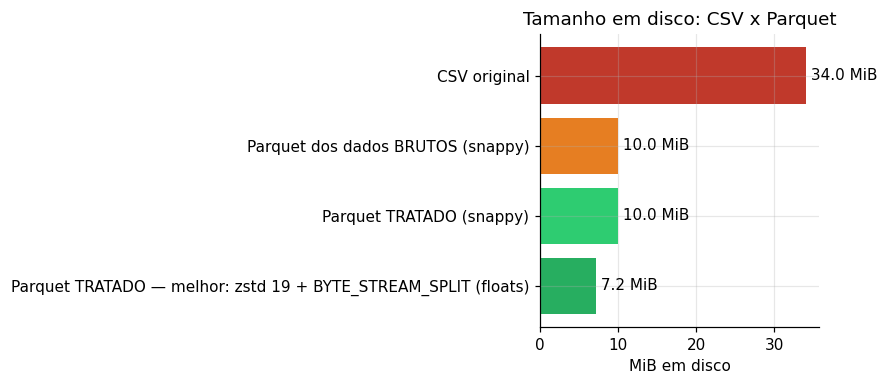


**Melhor configuração:** `zstd 19 + BYTE_STREAM_SPLIT (floats)` → **7.19 MiB** contra **34.00 MiB** do CSV
(**78.8% menor**, ou **4.7×** menos espaço).  
Arquivo final: `/content/NFL_tratado.parquet`


In [37]:
# 7.2 Escolha da melhor configuração e gravação do arquivo final
melhor = exp["bytes"].idxmin()
parquet_final = OUT_DIR / "NFL_tratado.parquet"
parquet_final.write_bytes(arquivos_tmp[melhor].read_bytes())
for p in arquivos_tmp.values():
    p.unlink(missing_ok=True)                     # remove arquivos temporários dos experimentos

# Parquet dos dados BRUTOS (só efeito do formato), para comparação justa
parquet_bruto = OUT_DIR / "_NFL_bruto_snappy.parquet"
try:
    bruto.to_parquet(parquet_bruto, index=False)
    tam_bruto_pq = parquet_bruto.stat().st_size
    parquet_bruto.unlink(missing_ok=True)
except Exception as erro:
    tam_bruto_pq = np.nan
    print("Parquet dos dados brutos não pôde ser gerado (tipos mistos):", str(erro)[:100])

tam_final = parquet_final.stat().st_size
tam_snappy = exp.loc["snappy (padrão)", "bytes"]
comparacao = pd.DataFrame({
    "arquivo": ["CSV original", "Parquet dos dados BRUTOS (snappy)", "Parquet TRATADO (snappy)", f"Parquet TRATADO — melhor: {melhor}"],
    "bytes": [base["csv_bytes"], tam_bruto_pq, tam_snappy, tam_final]})
comparacao["MiB"] = comparacao["bytes"] / MB
comparacao["redução vs CSV (%)"] = (1 - comparacao["bytes"] / base["csv_bytes"]) * 100
comparacao["razão CSV/arquivo"] = base["csv_bytes"] / comparacao["bytes"]
display(comparacao.set_index("arquivo"))

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(comparacao["arquivo"][::-1], comparacao["MiB"][::-1], color=["#27ae60", "#2ecc71", "#e67e22", "#c0392b"])
for i, v in enumerate(comparacao["MiB"][::-1]): ax.text(v, i, f" {v:,.1f} MiB", va="center")
ax.set_xlabel("MiB em disco"); ax.set_title("Tamanho em disco: CSV x Parquet")
plt.tight_layout(); plt.show()

md(f"""
**Melhor configuração:** `{melhor}` → **{tam_final/MB:,.2f} MiB** contra **{base['csv_bytes']/MB:,.2f} MiB** do CSV
(**{(1-tam_final/base['csv_bytes'])*100:.1f}% menor**, ou **{base['csv_bytes']/tam_final:.1f}×** menos espaço).
Arquivo final: `{parquet_final}`
""")

### Interpretação da compressão
* O **formato** Parquet sozinho já reduz o arquivo (comparar CSV × Parquet dos dados brutos).
* A **tipificação correta** (booleanos, inteiros pequenos, categorias, datas) reduz ainda mais, porque o Parquet passa a armazenar menos bits por valor e a dicionarizar melhor o texto.
* O **codec** muda o tamanho final: `snappy` privilegia velocidade; `zstd` com nível alto e `brotli` comprimem mais, ao custo de **escrita mais lenta** (a leitura continua rápida). Para armazenamento de longo prazo, o menor arquivo vale a espera.
* **Nada disso altera os dados**: a validação na próxima seção comprova.

<a id="8"></a>
## 8. Validação após o armazenamento
Leio o Parquet de volta e comparo com o DataFrame **exatamente como estava antes de gravar** (`df`). O teste de igualdade é **exato** (sem tolerância numérica): se um único valor mudar, o teste falha.

Verificações: número de linhas, nomes e ordem das colunas, tipos, ausentes por coluna, **igualdade completa dos valores** e um *hash* linha a linha.

In [38]:
t0 = time.time()
lido = pd.read_parquet(parquet_final)
tempo_leitura = time.time() - t0

checagens = []
def checar(nome, ok, detalhe=""):
    checagens.append({"verificação": nome, "resultado": "✅ OK" if ok else "❌ FALHOU", "detalhe": detalhe})

checar("mesmo número de linhas", lido.shape[0] == df.shape[0], f"{df.shape[0]:,} x {lido.shape[0]:,}")
checar("mesmas colunas, na mesma ordem", list(lido.columns) == list(df.columns), f"{df.shape[1]} colunas")

dif_tipos = {c: (str(df[c].dtype), str(lido[c].dtype)) for c in df.columns if str(df[c].dtype) != str(lido[c].dtype)}
checar("tipos idênticos (comparação estrita)", not dif_tipos, f"{len(dif_tipos)} colunas com representação diferente" if dif_tipos else "todos iguais")

aus_igual = bool((df.isna().sum() == lido.isna().sum()).all())
checar("mesma contagem de ausentes por coluna", aus_igual, f"{int(df.isna().sum().sum()):,} x {int(lido.isna().sum().sum()):,}")

try:
    pd.testing.assert_frame_equal(df, lido, check_dtype=False, check_exact=True)
    checar("valores idênticos (assert_frame_equal exato)", True, "nenhuma diferença")
except AssertionError as e:
    checar("valores idênticos (assert_frame_equal exato)", False, str(e)[:120])

h1 = pd.util.hash_pandas_object(df.astype({c: "object" for c in df.columns if str(df[c].dtype) in ("string", "str")}), index=False).to_numpy()
h2 = pd.util.hash_pandas_object(lido.astype({c: "object" for c in lido.columns if str(lido[c].dtype) in ("string", "str")}), index=False).to_numpy()
checar("hash linha a linha idêntico", bool(np.array_equal(h1, h2)), f"{(h1 != h2).sum()} linhas diferentes")

checar("linhas = bruto − duplicatas removidas", len(lido) == base["linhas"] - dup_exatas, f"{base['linhas']:,} − {dup_exatas} = {len(lido):,}")
display(pd.DataFrame(checagens).set_index("verificação"))
if dif_tipos:
    print("Diferenças de REPRESENTAÇÃO de tipo (os valores continuam idênticos, conforme o teste acima):")
    display(pd.DataFrame(dif_tipos, index=["antes de gravar", "depois de ler"]).T)
print(f"Tempo de leitura do Parquet: {tempo_leitura:.2f} s")

,resultado,detalhe
verificação,,
mesmo número de linhas,✅ OK,"51,429 x 51,429"
"mesmas colunas, na mesma ordem",✅ OK,105 colunas
tipos idênticos (comparação estrita),✅ OK,todos iguais
mesma contagem de ausentes por coluna,✅ OK,"1,404,752 x 1,404,752"
valores idênticos (assert_frame_equal exato),✅ OK,nenhuma diferença
hash linha a linha idêntico,✅ OK,0 linhas diferentes
linhas = bruto − duplicatas removidas,✅ OK,"51,429 − 0 = 51,429"


Tempo de leitura do Parquet: 0.33 s


In [39]:
# Prova visual por amostra: 5 linhas aleatórias lado a lado (antes de gravar x depois de ler)
amostra = df.sample(5, random_state=7).index
display(pd.concat({"antes": df.loc[amostra].iloc[:, :8], "depois": lido.loc[amostra].iloc[:, :8]}, axis=1))

antes                                                       \
            Date      GameID Drive qtr down            time TimeUnder   
35892 2009-12-13  2009121312    17   4    1 0 days 00:00:57         1   
29547 2009-11-29  2009112906    13   2    1 0 days 00:00:00         0   
16028 2009-10-25  2009102504     8   2    3 0 days 00:10:49        11   
33023 2009-12-06  2009120611     8   2    1 0 days 00:01:54         2   
37400 2009-12-20  2009122008    14   3    2 0 days 00:08:16         9   

                   depois                                             \
      TimeSecs       Date      GameID Drive qtr down            time   
35892       57 2009-12-13  2009121312    17   4    1 0 days 00:00:57   
29547     1800 2009-11-29  2009112906    13   2    1 0 days 00:00:00   
16028     2449 2009-10-25  2009102504     8   2    3 0 days 00:10:49   
33023     1914 2009-12-06  2009120611     8   2    1 0 days 00:01:54   
37400     1396 2009-12-20  2009122008    14   3    2 0 days 00:08:16   

                          
      TimeUnder TimeSecs  
35892         1       57  
29547         0     1800  
16028        11     2449  
33023         2     1914  
37400         9     1396

### Interpretação da validação
* O teste de igualdade é **exato** (`check_exact=True`): valores decimais, datas, durações, categorias e ausentes voltam **idênticos**.
* Se alguma coluna aparecer com representação de tipo diferente (por exemplo, o `string` do pandas lido de volta com outra implementação), isso é **diferença legítima de serialização**, e não perda de informação: o teste de valores e o *hash* linha a linha continuam sendo o critério de integridade.
* Conclusão: **o armazenamento em Parquet preservou os dados integralmente.**

<a id="9"></a>
## 9. Análise final
Resumo das transformações realizadas e das melhorias obtidas, com os números reais desta execução.

,Bruto,Tratado,Variação (%)
Linhas,"51,429.000","51,429.000",0.000
Colunas,102.000,105.000,2.941
Memória no pandas (MiB),102.930,27.942,-72.853
Tamanho em disco (MiB),34.000,7.192,-78.848
Células ausentes,"1,456,497.000","1,404,752.000",-3.553
Duplicatas exatas,0.000,0.000,NaN


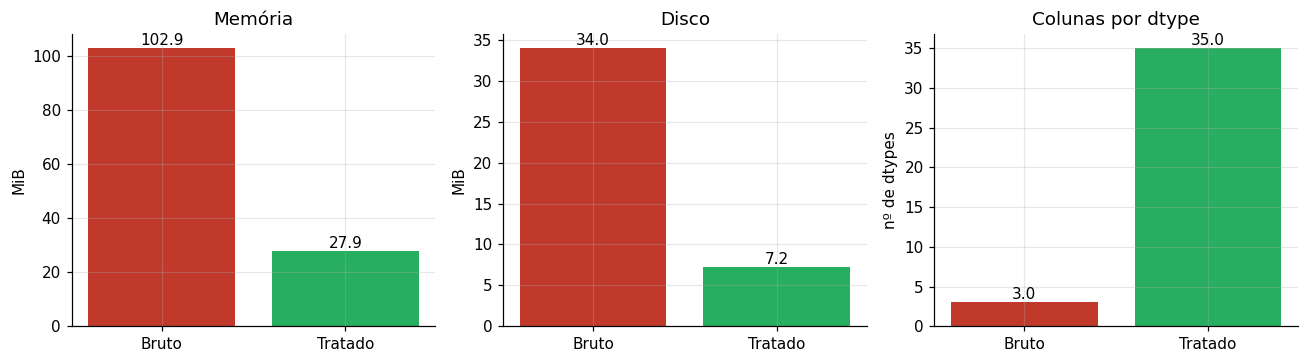

In [40]:
# 9.1 Painel antes x depois
aus_depois = int(df.isna().sum().sum())
resumo = pd.DataFrame({
    "Bruto": [base["linhas"], base["colunas"], base["memoria_bytes"] / MB, base["csv_bytes"] / MB, base["ausentes"], dup_bruto],
    "Tratado": [len(df), df.shape[1], mem_final / MB, tam_final / MB, aus_depois, int(df.duplicated().sum())]},
    index=["Linhas", "Colunas", "Memória no pandas (MiB)", "Tamanho em disco (MiB)", "Células ausentes", "Duplicatas exatas"])
resumo["Variação (%)"] = (resumo["Tratado"] / resumo["Bruto"] - 1) * 100
display(resumo)

fig, axs = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, (titulo, a, b, un) in zip(axs, [("Memória", base["memoria_bytes"] / MB, mem_final / MB, "MiB"),
                                         ("Disco", base["csv_bytes"] / MB, tam_final / MB, "MiB"),
                                         ("Colunas por dtype", len(bruto.dtypes.unique()), len(df.dtypes.unique()), "nº de dtypes")]):
    ax.bar(["Bruto", "Tratado"], [a, b], color=["#c0392b", "#27ae60"])
    for i, v in enumerate([a, b]): ax.text(i, v, f"{v:,.1f}", ha="center", va="bottom")
    ax.set_title(titulo); ax.set_ylabel(un)
plt.tight_layout(); plt.show()

In [41]:
# 9.2 Tudo o que foi alterado (a partir do log): resumo por etapa
log_df = pd.DataFrame(log)
display(log_df.groupby("etapa").agg(operações=("coluna", "size"), valores_afetados=("quantidade", "sum")))
print("Detalhe das operações que NÃO são conversão de tipo:")
display(log_df[log_df.etapa != "tipificação"].reset_index(drop=True) if (log_df.etapa != "tipificação").any()
        else pd.DataFrame({"resultado": ["apenas conversões de tipo foram necessárias"]}))

,operações,valores_afetados
etapa,,
ausentes,5,51745
saneamento,1,1
tipificação,80,4114320


Detalhe das operações que NÃO são conversão de tipo:


,etapa,coluna,quantidade,detalhe
0,saneamento,desc,1,espaços nas pontas removidos
1,ausentes,DefTwoPoint,51429,coluna 100% vazia removida
2,ausentes,yrdln,107,imputado com mediana (30)
3,ausentes,yrdline100,107,imputado com mediana (49)
4,ausentes,PlayTimeDiff,68,imputado com mediana (18)
5,ausentes,TimeSecs,34,imputado com mediana (1800)


In [42]:
# 9.3 Conclusão automática com os números desta execução
n_conv = int((log_df.etapa == "tipificação").sum())
md(f"""
## Conclusão

**Problemas encontrados no diagnóstico:** {base['linhas']:,} jogadas × {base['colunas']} atributos; {int((perfil.pct_ausentes > 90).sum())} colunas com mais de 90% de ausentes (eventos raros),
{len(mistas)} coluna(s) com tipos misturados, {len(susp)} com sujeira textual e {dup_bruto} duplicatas exatas; quase todos os tipos eram genéricos (`int64`/`float64`/`object`).

**Tipificação:** {n_conv} colunas convertidas para tipos que refletem o significado (datas, durações, booleanos, inteiros compactos, categorias),
**sem alterar nenhum valor** (auditoria coluna a coluna) e sem criar ausentes por falha de conversão.

**Ausentes:** classificados por causa (evento raro / estrutural / baixa incidência / parcial). A maioria foi **mantida como `NaN` por carregar informação**;
foram recuperados por cálculo exato ou imputados apenas {sum(l['quantidade'] for l in log if l['etapa']=='ausentes' and ('recuperado' in l['detalhe'] or 'imputado' in l['detalhe'])):,} valores, todos rastreáveis.

**Limpeza:** {dup_exatas} duplicatas exatas removidas, {total_unificados} categorias unificadas e
{int(log_df[(log_df.etapa=='limpeza') & log_df.detalhe.str.contains('domínio')].quantidade.sum())} valores impossíveis convertidos em ausente. Extremos legítimos preservados.

**Ganhos:**
| Métrica | Antes | Depois | Variação |
|---|---|---|---|
| Memória no pandas | {base['memoria_bytes']/MB:,.1f} MiB | {mem_final/MB:,.1f} MiB | **−{(1-mem_final/base['memoria_bytes'])*100:.1f}%** |
| Arquivo em disco | {base['csv_bytes']/MB:,.1f} MiB (CSV) | {tam_final/MB:,.1f} MiB (Parquet `{melhor}`) | **−{(1-tam_final/base['csv_bytes'])*100:.1f}%** ({base['csv_bytes']/tam_final:.1f}× menor) |

**Validação:** {sum(1 for c in checagens if c['resultado'].startswith('✅'))} de {len(checagens)} verificações aprovadas na releitura do Parquet.

### Limitações e próximos passos
* A classificação de ausências usa `PlayType` como explicação; ela indica **estrutura**, mas não prova o mecanismo (MCAR/MAR/MNAR).
* Colunas decimais ficaram em `float64` quando `float32` perderia precisão; usar `float32` reduziria mais o arquivo, **ao custo de fidelidade**, e portanto não foi feito.
* Regras de domínio de alerta (`ydstogo`, `TimeSecs`, `FieldGoalDistance`) só foram reportadas; confirmar com a documentação oficial do dataset permitiria torná-las regras fortes.
* Para análises que usem as colunas imputadas, filtrar pelo sinalizador `*_imputado` permite sensibilidade (com e sem estimativas).
""")


## Conclusão

**Problemas encontrados no diagnóstico:** 51,429 jogadas × 102 atributos; 17 colunas com mais de 90% de ausentes (eventos raros),
0 coluna(s) com tipos misturados, 1 com sujeira textual e 0 duplicatas exatas; quase todos os tipos eram genéricos (`int64`/`float64`/`object`).

**Tipificação:** 80 colunas convertidas para tipos que refletem o significado (datas, durações, booleanos, inteiros compactos, categorias),
**sem alterar nenhum valor** (auditoria coluna a coluna) e sem criar ausentes por falha de conversão.

**Ausentes:** classificados por causa (evento raro / estrutural / baixa incidência / parcial). A maioria foi **mantida como `NaN` por carregar informação**;
foram recuperados por cálculo exato ou imputados apenas 316 valores, todos rastreáveis.

**Limpeza:** 0 duplicatas exatas removidas, 0 categorias unificadas e
0 valores impossíveis convertidos em ausente. Extremos legítimos preservados.

**Ganhos:**
| Métrica | Antes | Depois | Variação |
|---|---|---|---|
| Memória no pandas | 102.9 MiB | 27.9 MiB | **−72.9%** |
| Arquivo em disco | 34.0 MiB (CSV) | 7.2 MiB (Parquet `zstd 19 + BYTE_STREAM_SPLIT (floats)`) | **−78.8%** (4.7× menor) |

**Validação:** 7 de 7 verificações aprovadas na releitura do Parquet.

### Limitações e próximos passos
* A classificação de ausências usa `PlayType` como explicação; ela indica **estrutura**, mas não prova o mecanismo (MCAR/MAR/MNAR).
* Colunas decimais ficaram em `float64` quando `float32` perderia precisão; usar `float32` reduziria mais o arquivo, **ao custo de fidelidade**, e portanto não foi feito.
* Regras de domínio de alerta (`ydstogo`, `TimeSecs`, `FieldGoalDistance`) só foram reportadas; confirmar com a documentação oficial do dataset permitiria torná-las regras fortes.
* Para análises que usem as colunas imputadas, filtrar pelo sinalizador `*_imputado` permite sensibilidade (com e sem estimativas).


---
**Reprodutibilidade:** execute as células na ordem (*Runtime ▸ Run all*). O notebook localiza o CSV automaticamente e grava `NFL_tratado.parquet` na pasta de saída.  
**Fonte dos dados:** *NFL Play by Play 2009-2017 (v4)*, Kaggle.